Rest task

Statistical Analysis-Boxplot representation

Friedman Test acorss all 4 models

In [ ]:
import numpy as np

early_fusion = np.array([
    0.7065,
    0.8087,
    0.8112,
    0.8644,
    0.8529
])

vanilla_dann = np.array([
    0.7672,
    0.8451,
    0.8740,
    0.8826,
    0.8829
])

baseline_scl = np.array([
    0.8057,
    0.8826,
    0.9297,
    0.9291,
    0.9199
])

proposed_model = np.array([
    0.9190,
    0.9615,
    0.9651,
    0.9787,
    0.9640
])

In [ ]:
from scipy.stats import friedmanchisquare

stat, p = friedmanchisquare(
    early_fusion,
    vanilla_dann,
    baseline_scl,
    proposed_model
)

print("====================================")
print(" Friedman Test")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")

if p < 0.05:
    print("\nSignificant difference exists among models.")
else:
    print("\nNo significant difference among models.")

 Friedman Test
Statistic : 15.0000
P-value   : 0.001817

Significant difference exists among models.


Wilcoxon test - pairwise analysis

proposed model vs early fusion

In [ ]:
from scipy.stats import wilcoxon

stat, p = wilcoxon(proposed_model, early_fusion)

print("\n====================================")
print(" Proposed vs Early Fusion")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs Early Fusion
Statistic : 0.0000
P-value   : 0.062500


proposed model vs vanilla dann

In [ ]:
stat, p = wilcoxon(proposed_model, vanilla_dann)

print("\n====================================")
print(" Proposed vs Vanilla DANN")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs Vanilla DANN
Statistic : 0.0000
P-value   : 0.062500


proposed model vs baseline scl

In [ ]:
stat, p = wilcoxon(proposed_model, baseline_scl)

print("\n====================================")
print(" Proposed vs SCL")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs SCL
Statistic : 0.0000
P-value   : 0.062500


Visualization

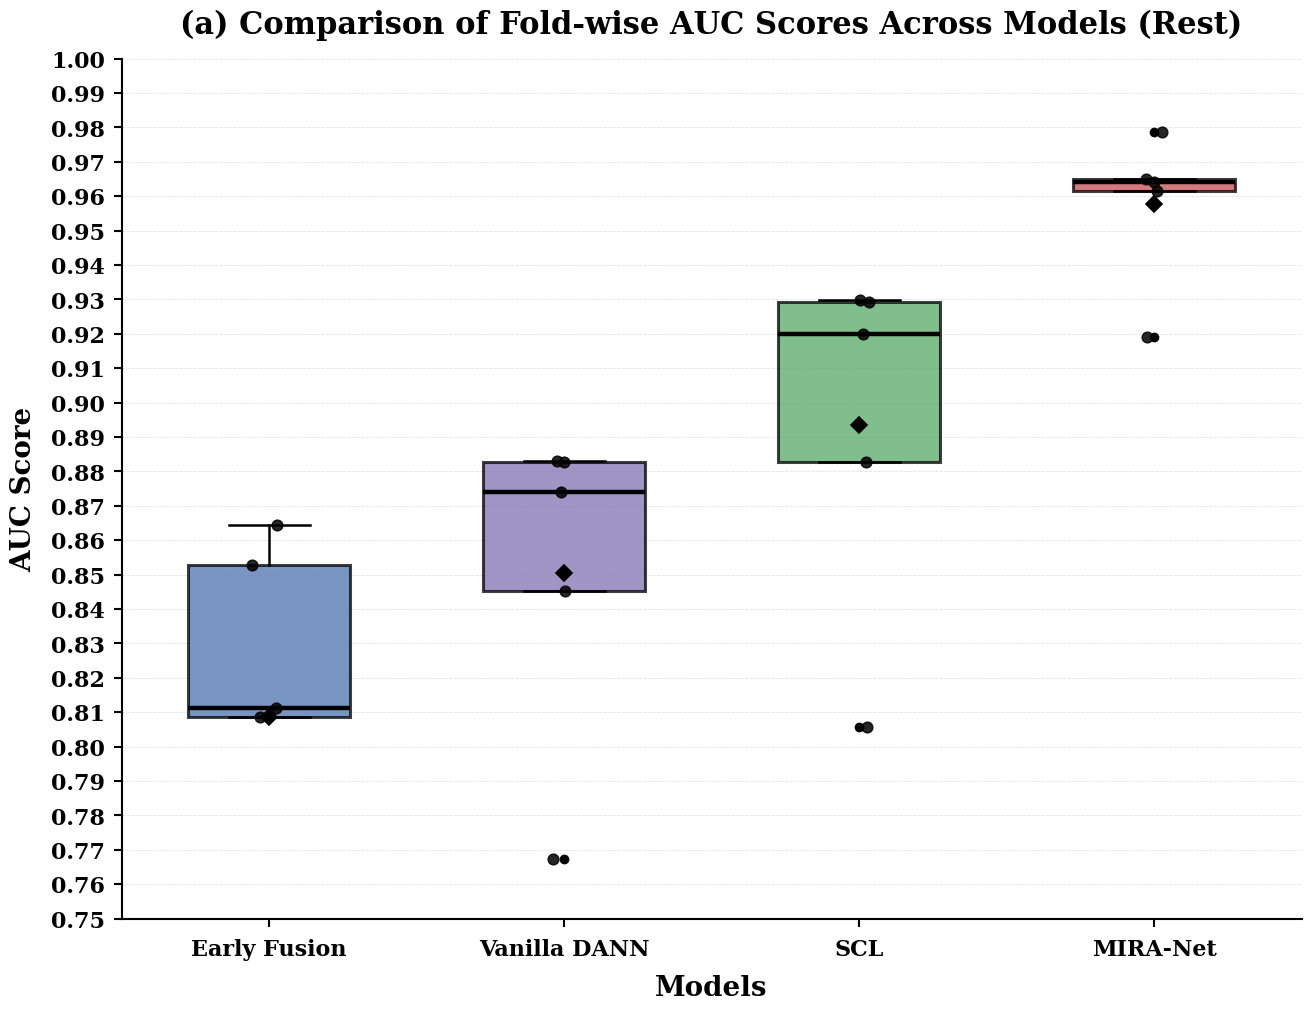

Saved Successfully!
Rest_AUC_Boxplot.pdf
Rest_AUC_Boxplot.svg


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files



plt.rcParams["font.family"] = "serif"      # Times New Roman if available
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# AUC SCORES
# ============================================================

early_fusion = np.array([
    0.7065,
    0.8087,
    0.8112,
    0.8644,
    0.8529
])

vanilla_dann = np.array([
    0.7672,
    0.8451,
    0.8740,
    0.8826,
    0.8829
])

baseline_scl = np.array([
    0.8057,
    0.8826,
    0.9297,
    0.9291,
    0.9199
])

proposed_model = np.array([
    0.9190,
    0.9615,
    0.9651,
    0.9787,
    0.9640
])

# ============================================================
# DATA
# ============================================================

data = [
    early_fusion,
    vanilla_dann,
    baseline_scl,
    proposed_model
]

labels = [
    "Early Fusion",
    "Vanilla DANN",
    "SCL",
    "MIRA-Net"
]

# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 10),
    constrained_layout=True
)

# ============================================================
# BOX PLOT
# ============================================================

box = ax.boxplot(

    data,

    tick_labels=labels,

    patch_artist=True,

    showmeans=True,

    widths=0.55,

    meanprops=dict(
        marker='D',
        markerfacecolor='black',
        markeredgecolor='black',
        markersize=8,
        markeredgewidth=1.2
    )
)

# ============================================================
# COLORS
# ============================================================

colors = [

    '#4C72B0',

    '#8172B2',

    '#55A868',

    '#C44E52'

]

# ============================================================
# BOX STYLING
# ============================================================

for patch, color in zip(box['boxes'], colors):

    patch.set_facecolor(color)

    patch.set_alpha(0.75)

    patch.set_edgecolor('black')

    patch.set_linewidth(2.2)

for median in box['medians']:

    median.set_color('black')

    median.set_linewidth(3.2)

for whisker in box['whiskers']:

    whisker.set_color('black')

    whisker.set_linewidth(1.8)

for cap in box['caps']:

    cap.set_color('black')

    cap.set_linewidth(1.8)

for flier in box['fliers']:

    flier.set(
        marker='o',
        markerfacecolor='black',
        markeredgecolor='black',
        markersize=6
    )

ax.margins(x=0.08)

# ============================================================
# INDIVIDUAL FOLD VALUES
# ============================================================

rng = np.random.default_rng(42)

for i, vals in enumerate(data, start=1):

    x = rng.normal(
        i,
        0.03,
        len(vals)
    )

    ax.scatter(
        x,
        vals,
        color='black',
        s=60,
        alpha=0.85,
        zorder=5
    )

# ============================================================
# LABELS
# ============================================================

ax.set_ylabel(
    "AUC Score",
    fontsize=20,
    fontweight='semibold',
    labelpad=10
)

ax.set_xlabel(
    "Models",
    fontsize=20,
    fontweight='semibold',
    labelpad=10
)

ax.set_title(
    "(a) Comparison of Fold-wise AUC Scores Across Models (Rest)",
    fontsize=22,
    fontweight='bold',
    pad=18
)

# ============================================================
# Y-AXIS
# ============================================================

# Y-axis range
ax.set_ylim(0.75, 1.00)

# Ticks from 0.75 to 1.00 at intervals of 0.01
ax.set_yticks(
    np.arange(
        0.75,
        1.001,
        0.01
    )
)

# Display tick labels with two decimal places
ax.set_yticklabels(
    [
        f"{tick:.2f}"
        for tick in np.arange(
            0.75,
            1.001,
            0.01
        )
    ]
)

# ============================================================
# TICK SETTINGS
# ============================================================

ax.tick_params(
    axis='both',
    labelsize=16,
    direction='out',
    length=6,
    width=1.5
)

ax.tick_params(
    axis='x',
    pad=8
)

ax.tick_params(
    axis='y',
    pad=6
)

# ============================================================
# SEMIBOLD TICK LABELS
# ============================================================

for tick in ax.get_xticklabels():

    tick.set_fontweight("semibold")

for tick in ax.get_yticklabels():

    tick.set_fontweight("semibold")

# ============================================================
# HORIZONTAL GRIDLINES
# ============================================================

ax.grid(
    axis='y',
    which='major',
    linestyle='--',
    linewidth=0.6,
    alpha=0.35
)

ax.set_axisbelow(True)

# ============================================================
# SPINES
# ============================================================

ax.spines['top'].set_visible(False)

ax.spines['right'].set_visible(False)

ax.spines['left'].set_linewidth(1.5)

ax.spines['bottom'].set_linewidth(1.5)

# ============================================================
# BACKGROUND
# ============================================================

fig.patch.set_facecolor("white")

ax.set_facecolor("white")

# ============================================================
# SAVE
# ============================================================

pdf_name = "Rest_AUC_Boxplot.pdf"

svg_name = "Rest_AUC_Boxplot.svg"

plt.savefig(
    pdf_name,
    format='pdf',
    dpi=600,
    bbox_inches='tight',
    transparent=False
)

plt.savefig(
    svg_name,
    format='svg',
    dpi=600,
    bbox_inches='tight',
    transparent=False
)

plt.show()

plt.close()

# ============================================================
# OUTPUT
# ============================================================

print("Saved Successfully!")

print(pdf_name)

print(svg_name)



In [ ]:
files.download(svg_name)
files.download(pdf_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Go task

Statistical Analysis with Ablation Models

Friedman Test acorss all 4 models

In [1]:
import numpy as np

early_fusion = np.array([
    0.7804,
    0.8158,
    0.7768,
    0.8674,
    0.7608
])

vanilla_dann = np.array([
    0.7945,
    0.8512,
    0.9337,
    0.8998,
    0.7908
])

baseline_scl = np.array([
    0.8168,
    0.8350,
    0.9226,
    0.9221,
    0.7948
])

proposed_model = np.array([
    0.8421,
    0.8907,
    0.9367,
    0.9342,
    0.8879
])

In [2]:
from scipy.stats import friedmanchisquare

stat, p = friedmanchisquare(
    early_fusion,
    vanilla_dann,
    baseline_scl,
    proposed_model
)

print("====================================")
print(" Friedman Test")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")

if p < 0.05:
    print("\nSignificant difference exists among models.")
else:
    print("\nNo significant difference among models.")

 Friedman Test
Statistic : 13.5600
P-value   : 0.003570

Significant difference exists among models.


Wilcoxon test - pairwise analysis

proposed model vs early fusion

In [3]:
from scipy.stats import wilcoxon

stat, p = wilcoxon(proposed_model, early_fusion)

print("\n====================================")
print(" Proposed vs Early Fusion")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs Early Fusion
Statistic : 0.0000
P-value   : 0.062500


proposed model vs vanilla dann

In [4]:
stat, p = wilcoxon(proposed_model, vanilla_dann)

print("\n====================================")
print(" Proposed vs Vanilla DANN")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs Vanilla DANN
Statistic : 0.0000
P-value   : 0.062500


proposed model vs baseline scl

In [5]:
stat, p = wilcoxon(proposed_model, baseline_scl)

print("\n====================================")
print(" Proposed vs SCL")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs SCL
Statistic : 0.0000
P-value   : 0.062500


Visualization

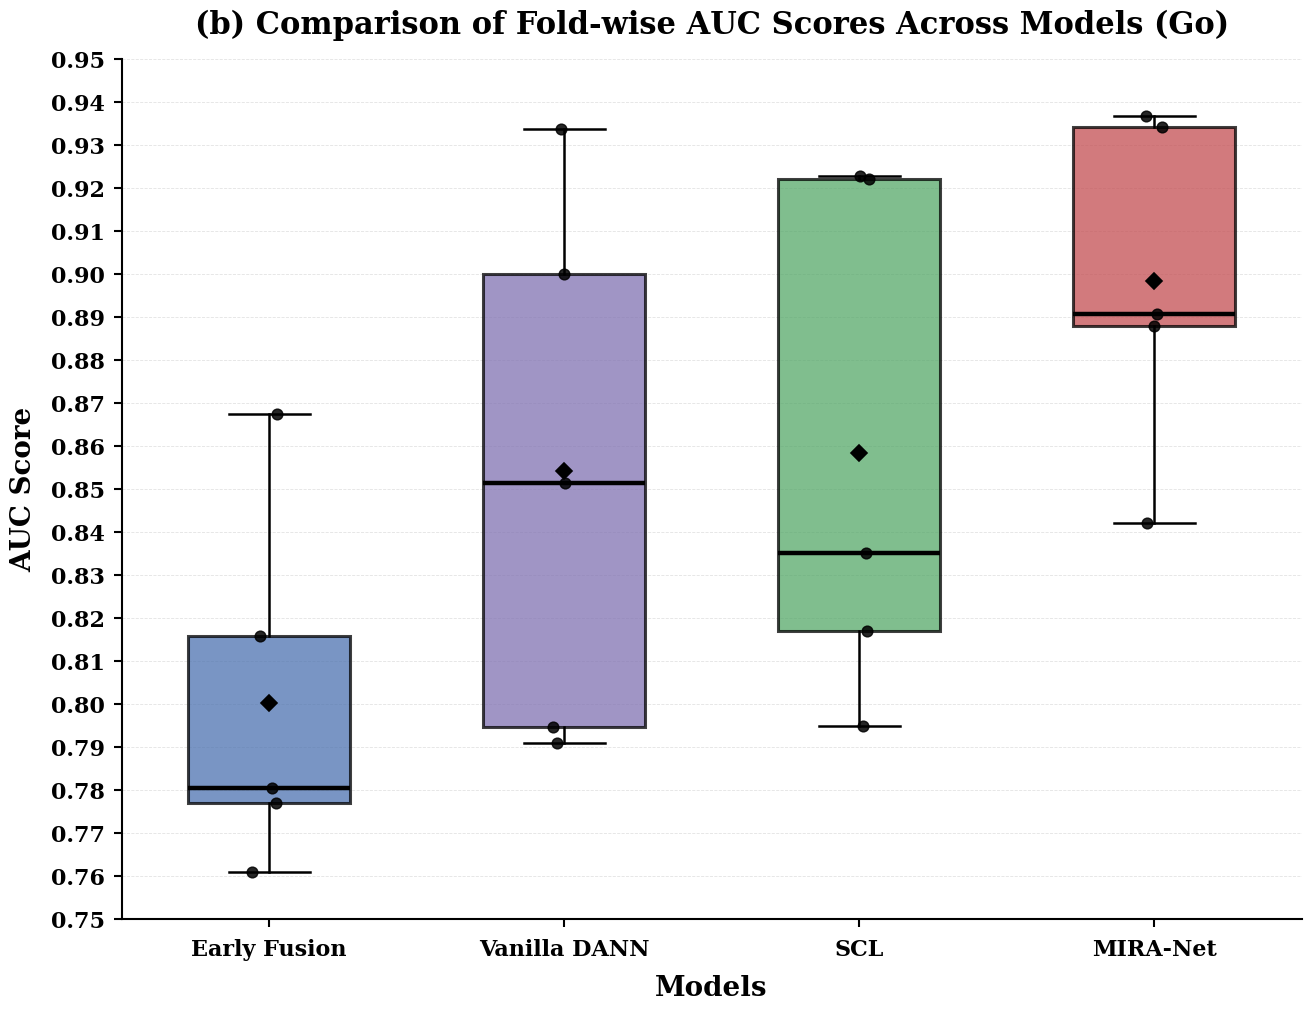

Saved Successfully!
Go_AUC_Boxplot.pdf
Go_AUC_Boxplot.svg


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

# ============================================================
# IEEE JBHI Plot Settings
# ============================================================

plt.rcParams["font.family"] = "serif"      # Times New Roman if available
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# AUC SCORES
# ============================================================

import numpy as np

early_fusion = np.array([
    0.7804,
    0.8158,
    0.7768,
    0.8674,
    0.7608
])

vanilla_dann = np.array([
    0.7945,
    0.8512,
    0.9337,
    0.8998,
    0.7908
])

baseline_scl = np.array([
    0.8168,
    0.8350,
    0.9226,
    0.9221,
    0.7948
])

proposed_model = np.array([
    0.8421,
    0.8907,
    0.9367,
    0.9342,
    0.8879
])

# ============================================================
# DATA
# ============================================================

data = [
    early_fusion,
    vanilla_dann,
    baseline_scl,
    proposed_model
]

labels = [
    "Early Fusion",
    "Vanilla DANN",
    "SCL",
    "MIRA-Net"
]

# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(13,10),
    constrained_layout=True
)

box = ax.boxplot(

    data,

    tick_labels=labels,

    patch_artist=True,

    showmeans=True,

    widths=0.55,

    meanprops=dict(

        marker='D',

        markerfacecolor='black',

        markeredgecolor='black',

        markersize=8,
        markeredgewidth=1.2

    )
)

# ============================================================
# COLORS
# ============================================================

colors = [

    '#4C72B0',

    '#8172B2',

    '#55A868',

    '#C44E52'

]

# ============================================================
# BOX STYLING
# ============================================================

for patch, color in zip(box['boxes'], colors):

    patch.set_facecolor(color)

    patch.set_alpha(0.75)

    patch.set_edgecolor('black')

    patch.set_linewidth(2.2)

for median in box['medians']:

    median.set_color('black')

    median.set_linewidth(3.2)

for whisker in box['whiskers']:

    whisker.set_color('black')

    whisker.set_linewidth(1.8)

for cap in box['caps']:

    cap.set_color('black')

    cap.set_linewidth(1.8)

for flier in box['fliers']:

    flier.set(

        marker='o',

        markerfacecolor='black',

        markeredgecolor='black',

        markersize=6

    )
ax.margins(x=0.08)

# ============================================================
# INDIVIDUAL FOLD VALUES
# ============================================================

rng = np.random.default_rng(42)   # Reproducible jitter

for i, vals in enumerate(data, start=1):

        x = rng.normal(i, 0.03, len(vals))   # Small horizontal spread

        ax.scatter(
            x,
            vals,
            color='black',
            s=60,
            alpha=0.85,
            zorder=5
        )

# ============================================================
# LABELS
# ============================================================

ax.set_ylabel(

    "AUC Score",

    fontsize=20,

    fontweight='semibold',
    labelpad=10

)

ax.set_xlabel(

    "Models",

    fontsize=20,

    fontweight='semibold',
    labelpad=10

)

ax.set_title(

    "(b) Comparison of Fold-wise AUC Scores Across Models (Go)",

    fontsize=22,

    fontweight='bold',

    pad=18

)

# ============================================================
# AXES
# ============================================================

ax.set_ylim(0.75,0.95)

ax.set_yticks(

    np.arange(0.75,0.951,0.01)

)

ax.tick_params(

    axis='both',

    labelsize=16,

    direction='out',

    length=6,

    width=1.5

)

ax.tick_params(axis='x', pad=8)
ax.tick_params(axis='y', pad=6)

# Make tick labels semibold
for tick in ax.get_xticklabels():

    tick.set_fontweight("semibold")

for tick in ax.get_yticklabels():

    tick.set_fontweight("semibold")

# ============================================================
# GRID
# ============================================================

ax.grid(

    axis='y',

    linestyle='--',

    linewidth=0.6,

    alpha=0.35

)

ax.set_axisbelow(True)
# ============================================================
# SPINES
# ============================================================

ax.spines['top'].set_visible(False)

ax.spines['right'].set_visible(False)

ax.spines['left'].set_linewidth(1.5)

ax.spines['bottom'].set_linewidth(1.5)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ============================================================
# SAVE
# ============================================================

pdf_name = "Go_AUC_Boxplot.pdf"

svg_name = "Go_AUC_Boxplot.svg"



plt.savefig(

    pdf_name,

    format='pdf',
    dpi=600,

    bbox_inches='tight',

    transparent=False

)

plt.savefig(

    svg_name,

    format='svg',
    dpi=600,

    bbox_inches='tight',

    transparent=False

)



plt.show()

plt.close()

print("Saved Successfully!")

print(pdf_name)

print(svg_name)



# Optional Downloads
# files.download(pdf_name)
# files.download(svg_name)
#

In [7]:
files.download(svg_name)
files.download(pdf_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Passive task

Statistical Analysis with Ablation Models

Friedman Test acorss all 4 models

In [1]:
import numpy as np

early_fusion = np.array([
    0.7176,
    0.8097,
    0.8730,
    0.8725,
    0.8498
])

vanilla_dann = np.array([
    0.7824,
    0.9413,
    0.9246,
    0.9302,
    0.8889
])

baseline_scl = np.array([
    0.8462,
    0.9322,
    0.9408,
    0.9676,
    0.9199
])

proposed_model = np.array([
    0.9474,
    0.9818,
    0.9813,
    0.9879,
    0.9860
])

In [2]:
from scipy.stats import friedmanchisquare

stat, p = friedmanchisquare(
    early_fusion,
    vanilla_dann,
    baseline_scl,
    proposed_model
)

print("====================================")
print(" Friedman Test")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")

if p < 0.05:
    print("\nSignificant difference exists among models.")
else:
    print("\nNo significant difference among models.")

 Friedman Test
Statistic : 14.0400
P-value   : 0.002851

Significant difference exists among models.


Wilcoxon test - pairwise analysis

proposed model vs early fusion

In [3]:
from scipy.stats import wilcoxon

stat, p = wilcoxon(proposed_model, early_fusion)

print("\n====================================")
print(" Proposed vs Early Fusion")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs Early Fusion
Statistic : 0.0000
P-value   : 0.062500


proposed model vs vanilla dann

In [4]:
stat, p = wilcoxon(proposed_model, vanilla_dann)

print("\n====================================")
print(" Proposed vs Vanilla DANN")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs Vanilla DANN
Statistic : 0.0000
P-value   : 0.062500


proposed model vs baseline scl

In [5]:
stat, p = wilcoxon(proposed_model, baseline_scl)

print("\n====================================")
print(" Proposed vs SCL")
print("====================================")

print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p:.6f}")


 Proposed vs SCL
Statistic : 0.0000
P-value   : 0.062500


Visualization

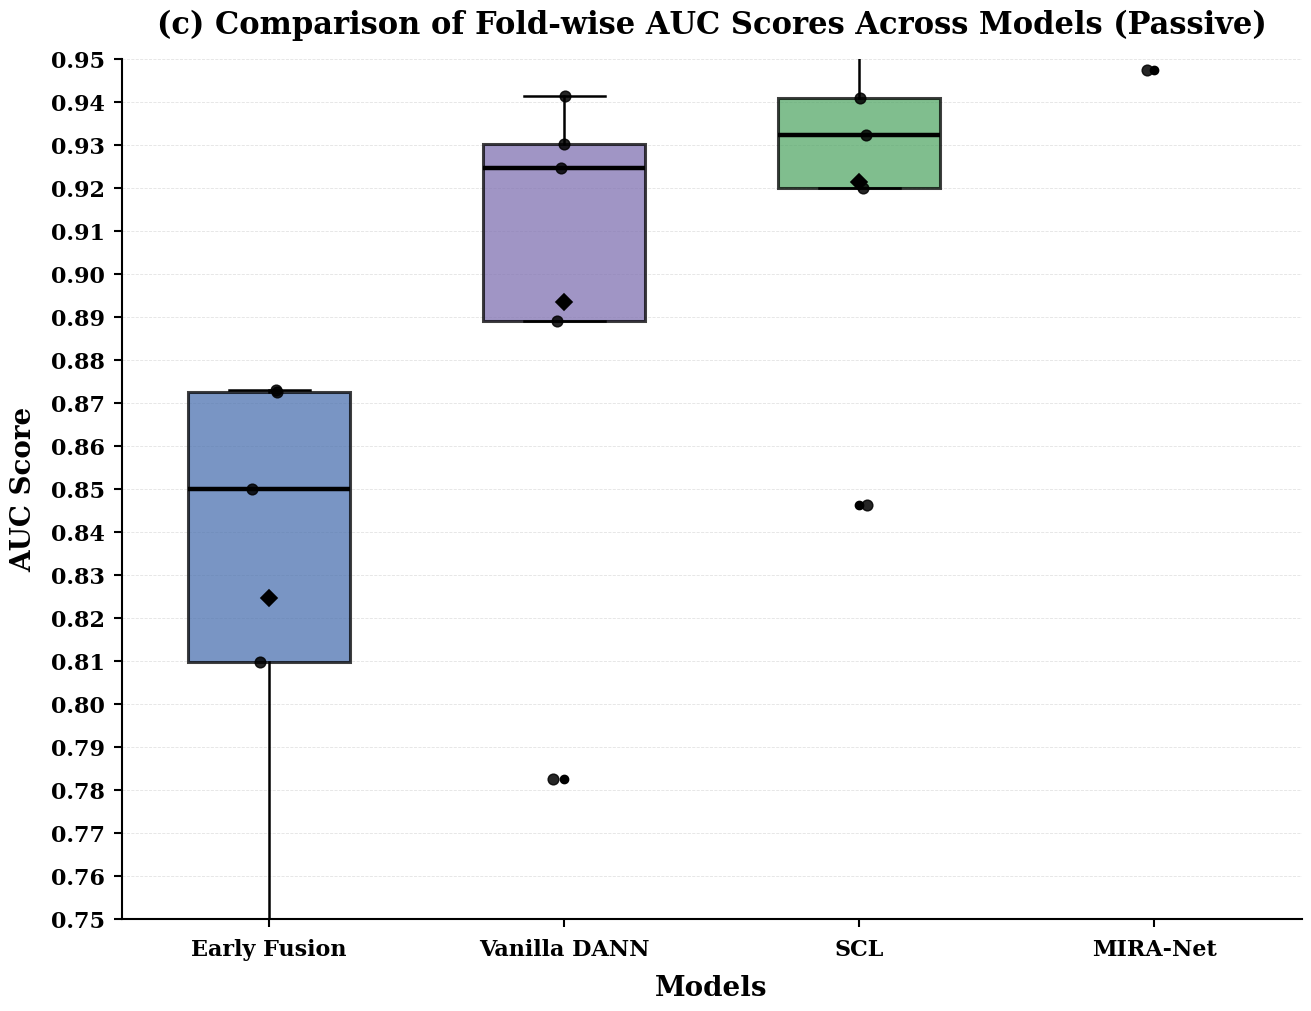

Saved Successfully!
Passive_AUC_Boxplot.pdf
Passive_AUC_Boxplot.svg


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

# ============================================================
# IEEE JBHI Plot Settings
# ============================================================

plt.rcParams["font.family"] = "serif"      # Times New Roman if available
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# AUC SCORES
# ============================================================

early_fusion = np.array([
    0.7176,
    0.8097,
    0.8730,
    0.8725,
    0.8498
])

vanilla_dann = np.array([
    0.7824,
    0.9413,
    0.9246,
    0.9302,
    0.8889
])

baseline_scl = np.array([
    0.8462,
    0.9322,
    0.9408,
    0.9676,
    0.9199
])

proposed_model = np.array([
    0.9474,
    0.9818,
    0.9813,
    0.9879,
    0.9860
])

# ============================================================
# DATA
# ============================================================

data = [
    early_fusion,
    vanilla_dann,
    baseline_scl,
    proposed_model
]

labels = [
    "Early Fusion",
    "Vanilla DANN",
    "SCL",
    "MIRA-Net"
]

# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(13,10),
    constrained_layout=True
)

box = ax.boxplot(

    data,

    tick_labels=labels,

    patch_artist=True,

    showmeans=True,

    widths=0.55,

    meanprops=dict(

        marker='D',

        markerfacecolor='black',

        markeredgecolor='black',

        markersize=8,
        markeredgewidth=1.2

    )
)

# ============================================================
# COLORS
# ============================================================

colors = [

    '#4C72B0',

    '#8172B2',

    '#55A868',

    '#C44E52'

]

# ============================================================
# BOX STYLING
# ============================================================

for patch, color in zip(box['boxes'], colors):

    patch.set_facecolor(color)

    patch.set_alpha(0.75)

    patch.set_edgecolor('black')

    patch.set_linewidth(2.2)

for median in box['medians']:

    median.set_color('black')

    median.set_linewidth(3.2)

for whisker in box['whiskers']:

    whisker.set_color('black')

    whisker.set_linewidth(1.8)

for cap in box['caps']:

    cap.set_color('black')

    cap.set_linewidth(1.8)

for flier in box['fliers']:

    flier.set(

        marker='o',

        markerfacecolor='black',

        markeredgecolor='black',

        markersize=6

    )
ax.margins(x=0.08)

# ============================================================
# INDIVIDUAL FOLD VALUES
# ============================================================

rng = np.random.default_rng(42)   # Reproducible jitter

for i, vals in enumerate(data, start=1):

        x = rng.normal(i, 0.03, len(vals))   # Small horizontal spread

        ax.scatter(
            x,
            vals,
            color='black',
            s=60,
            alpha=0.85,
            zorder=5
        )

# ============================================================
# LABELS
# ============================================================

ax.set_ylabel(

    "AUC Score",

    fontsize=20,

    fontweight='semibold',
    labelpad=10

)

ax.set_xlabel(

    "Models",

    fontsize=20,

    fontweight='semibold',
    labelpad=10

)

ax.set_title(

    "(c) Comparison of Fold-wise AUC Scores Across Models (Passive)",

    fontsize=22,

    fontweight='bold',

    pad=18

)

# ============================================================
# AXES
# ============================================================

ax.set_ylim(0.75,0.95)

ax.set_yticks(

    np.arange(0.75,0.951,0.01)

)

ax.tick_params(

    axis='both',

    labelsize=16,

    direction='out',

    length=6,

    width=1.5

)

ax.tick_params(axis='x', pad=8)
ax.tick_params(axis='y', pad=6)

# Make tick labels semibold
for tick in ax.get_xticklabels():

    tick.set_fontweight("semibold")

for tick in ax.get_yticklabels():

    tick.set_fontweight("semibold")

# ============================================================
# GRID
# ============================================================

ax.grid(

    axis='y',

    linestyle='--',

    linewidth=0.6,

    alpha=0.35

)

ax.set_axisbelow(True)
# ============================================================
# SPINES
# ============================================================

ax.spines['top'].set_visible(False)

ax.spines['right'].set_visible(False)

ax.spines['left'].set_linewidth(1.5)

ax.spines['bottom'].set_linewidth(1.5)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ============================================================
# SAVE
# ============================================================

pdf_name = "Passive_AUC_Boxplot.pdf"

svg_name = "Passive_AUC_Boxplot.svg"



plt.savefig(

    pdf_name,

    format='pdf',
    dpi=600,

    bbox_inches='tight',

    transparent=False

)

plt.savefig(

    svg_name,

    format='svg',
    dpi=600,

    bbox_inches='tight',

    transparent=False

)



plt.show()

plt.close()

print("Saved Successfully!")

print(pdf_name)

print(svg_name)



# Optional Downloads
# files.download(pdf_name)
# files.download(svg_name)
#

In [7]:
files.download(svg_name)
files.download(pdf_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Combining all three

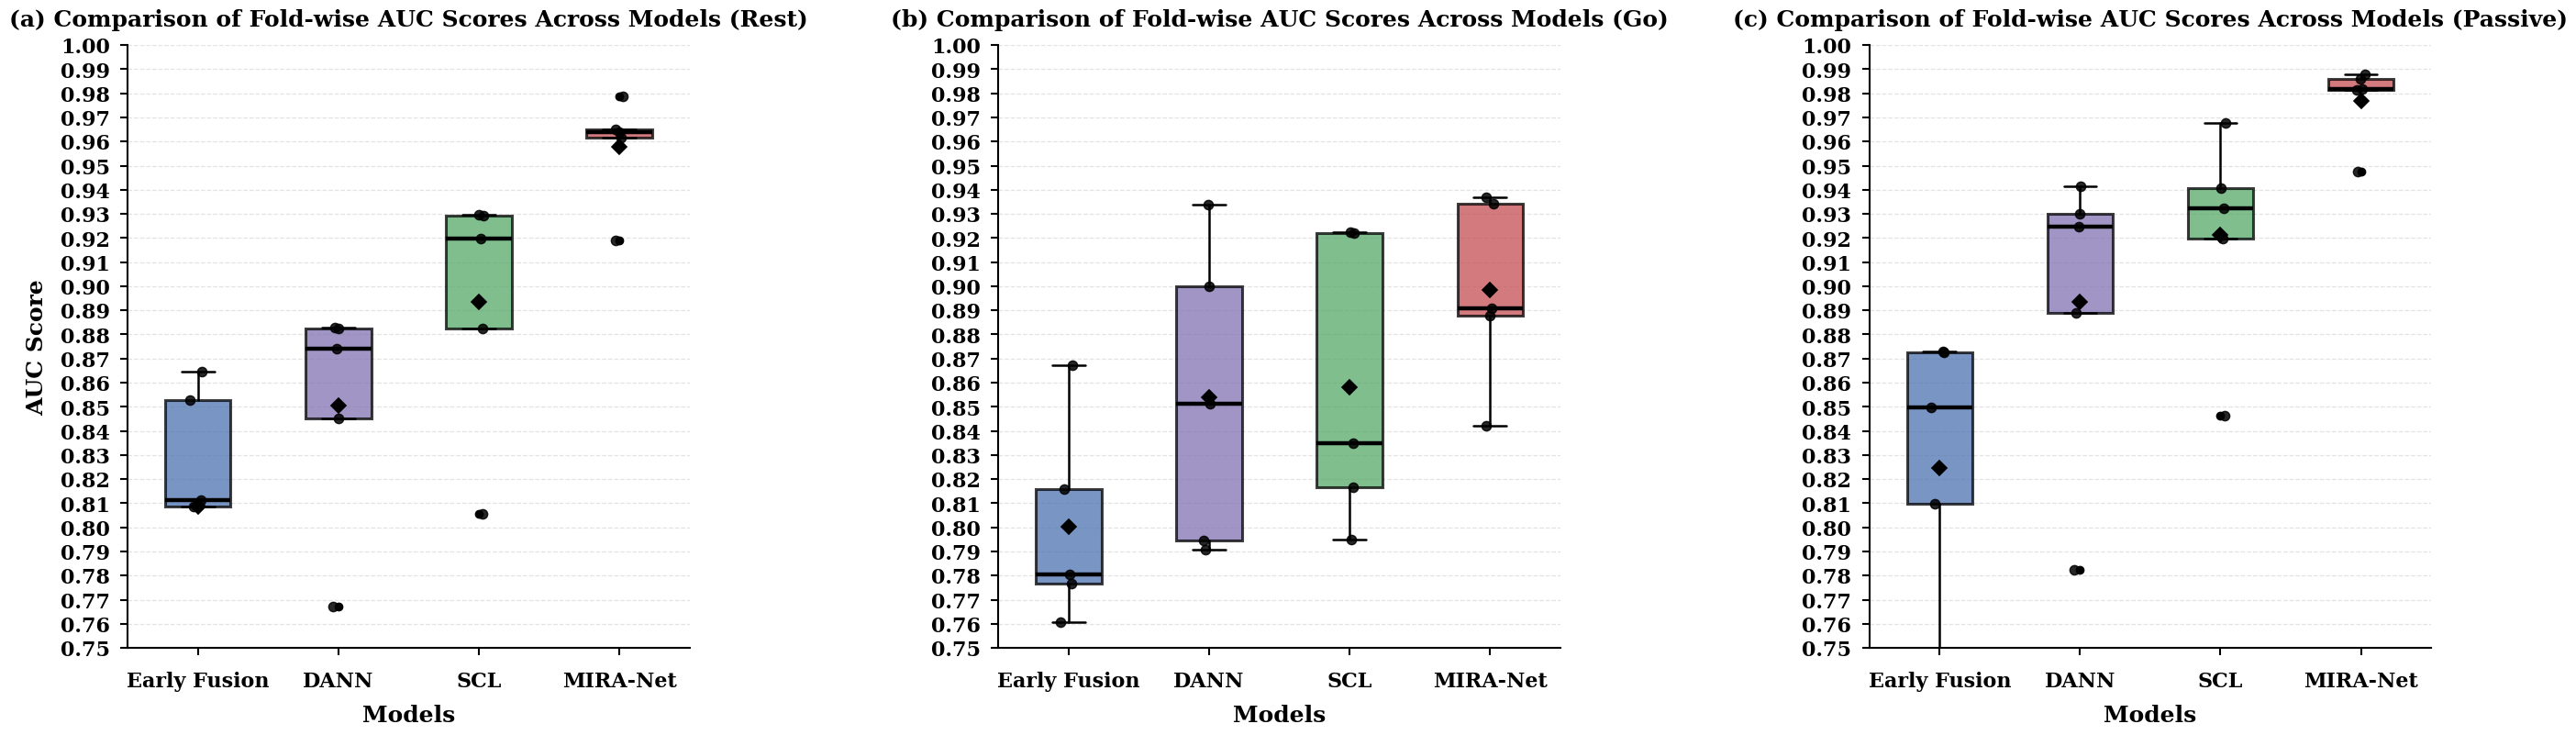

Saved Successfully!
PDF:
/content/auc_boxplots/AUC_Boxplots_Rest_Go_Passive.pdf

SVG:
/content/auc_boxplots/AUC_Boxplots_Rest_Go_Passive.svg


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import os


# ============================================================
# IEEE JBHI Plot Settings
# ============================================================

plt.rcParams["font.family"] = "serif"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42


# ============================================================
# REST DATA
# ============================================================

rest_data = [

    np.array([
        0.7065,
        0.8087,
        0.8112,
        0.8644,
        0.8529
    ]),

    np.array([
        0.7672,
        0.8451,
        0.8740,
        0.8826,
        0.8829
    ]),

    np.array([
        0.8057,
        0.8826,
        0.9297,
        0.9291,
        0.9199
    ]),

    np.array([
        0.9190,
        0.9615,
        0.9651,
        0.9787,
        0.9640
    ])
]


# ============================================================
# GO DATA
# ============================================================

go_data = [

    np.array([
        0.7804,
        0.8158,
        0.7768,
        0.8674,
        0.7608
    ]),

    np.array([
        0.7945,
        0.8512,
        0.9337,
        0.8998,
        0.7908
    ]),

    np.array([
        0.8168,
        0.8350,
        0.9226,
        0.9221,
        0.7948
    ]),

    np.array([
        0.8421,
        0.8907,
        0.9367,
        0.9342,
        0.8879
    ])
]


# ============================================================
# PASSIVE DATA
# ============================================================

passive_data = [

    np.array([
        0.7176,
        0.8097,
        0.8730,
        0.8725,
        0.8498
    ]),

    np.array([
        0.7824,
        0.9413,
        0.9246,
        0.9302,
        0.8889
    ]),

    np.array([
        0.8462,
        0.9322,
        0.9408,
        0.9676,
        0.9199
    ]),

    np.array([
        0.9474,
        0.9818,
        0.9813,
        0.9879,
        0.9860
    ])
]


# ============================================================
# LABELS
# ============================================================

labels = [
    "Early Fusion",
    "DANN",
    "SCL",
    "MIRA-Net"
]


# ============================================================
# COLORS (IEEE Friendly)
# ============================================================

colors = [
    "#4C72B0",
    "#8172B2",
    "#55A868",
    "#C44E52"
]


# ============================================================
# DRAW BOXPLOT FUNCTION
# ============================================================

def draw_boxplot(ax, data, title, show_ylabel=False):

    # --------------------------------------------------------
    # Increase horizontal spacing between model positions
    # --------------------------------------------------------

    positions = np.array([1.0, 2.5, 4.0, 5.5])

    box = ax.boxplot(

        data,

        positions=positions,

        tick_labels=labels,

        patch_artist=True,

        showmeans=True,

        widths=0.70,

        meanprops=dict(

            marker='D',

            markerfacecolor='black',

            markeredgecolor='black',

            markeredgewidth=1.2,

            markersize=8
        )
    )


    # --------------------------------------------------------
    # Colors
    # --------------------------------------------------------

    for patch, color in zip(box['boxes'], colors):

        patch.set_facecolor(color)

        patch.set_alpha(0.75)

        patch.set_edgecolor("black")

        patch.set_linewidth(2.2)


    # --------------------------------------------------------
    # Median
    # --------------------------------------------------------

    for median in box['medians']:

        median.set_color("black")

        median.set_linewidth(3.2)


    # --------------------------------------------------------
    # Whiskers
    # --------------------------------------------------------

    for whisker in box['whiskers']:

        whisker.set_color("black")

        whisker.set_linewidth(1.8)

        whisker.set_solid_capstyle("round")


    # --------------------------------------------------------
    # Caps
    # --------------------------------------------------------

    for cap in box['caps']:

        cap.set_color("black")

        cap.set_linewidth(1.8)

        cap.set_solid_capstyle("round")


    # --------------------------------------------------------
    # Outliers
    # --------------------------------------------------------

    for flier in box['fliers']:

        flier.set(

            marker='o',

            markerfacecolor='black',

            markeredgecolor='black',

            markersize=6
        )


    # --------------------------------------------------------
    # Individual folds with jitter
    # --------------------------------------------------------

    rng = np.random.default_rng(42)

    for i, vals in enumerate(data):

        x = rng.normal(
            positions[i],
            0.045,
            len(vals)
        )

        ax.scatter(

            x,

            vals,

            color="black",

            s=55,

            alpha=0.85,

            zorder=5
        )


    # --------------------------------------------------------
    # Titles
    # --------------------------------------------------------

    ax.set_title(

        title,

        fontsize=18,

        fontweight="bold",

        pad=15
    )


    # --------------------------------------------------------
    # X-axis
    # --------------------------------------------------------

    ax.set_xlabel(

        "Models",

        fontsize=18,

        fontweight="semibold",

        labelpad=10
    )


    # --------------------------------------------------------
    # Y-axis
    # --------------------------------------------------------

    if show_ylabel:

        ax.set_ylabel(

            "AUC Score",

            fontsize=18,

            fontweight="semibold",

            labelpad=10
        )

    else:

        ax.set_ylabel("")


    # --------------------------------------------------------
    # Axis Range
    # --------------------------------------------------------

    ax.set_ylim(
        0.75,
        1.00
    )

    ax.set_yticks(
        np.arange(
            0.75,
            1.001,
            0.01
        )
    )


    # Explicit y-axis formatting

    ax.set_yticklabels(
        [
            f"{value:.2f}"
            for value in np.arange(
                0.75,
                1.001,
                0.01
            )
        ]
    )


    # --------------------------------------------------------
    # X-axis range
    # --------------------------------------------------------

    ax.set_xlim(
        0.25,
        6.25
    )


    # --------------------------------------------------------
    # Tick Parameters
    # --------------------------------------------------------

    ax.tick_params(

        axis='y',

        labelsize=16,

        direction='out',

        length=6,

        width=1.5,

        pad=8
    )


    ax.tick_params(

        axis='x',

        labelsize=16,

        direction='out',

        length=6,

        width=1.5,

        pad=12
    )


    # --------------------------------------------------------
    # Tick Font
    # --------------------------------------------------------

    for tick in ax.get_xticklabels():

        tick.set_fontweight("semibold")

        tick.set_horizontalalignment("center")


    for tick in ax.get_yticklabels():

        tick.set_fontweight("semibold")


    # --------------------------------------------------------
    # Horizontal Grid Lines
    # --------------------------------------------------------
    # Slightly thicker than before
    # Length remains exactly the width of each subplot
    # --------------------------------------------------------

    ax.grid(

        axis='y',

        which='major',

        linestyle='--',

        linewidth=0.9,

        alpha=0.35
    )

    ax.set_axisbelow(True)


    # --------------------------------------------------------
    # Spines
    # --------------------------------------------------------

    ax.spines["top"].set_visible(False)

    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(1.5)

    ax.spines["bottom"].set_linewidth(1.5)


    # --------------------------------------------------------
    # Background
    # --------------------------------------------------------

    ax.set_facecolor("white")


# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(

    1,

    3,

    figsize=(27, 9),

    constrained_layout=False
)


# ============================================================
# DRAW THREE SUBPLOTS
# ============================================================

draw_boxplot(

    axes[0],

    rest_data,

    "(a) Comparison of Fold-wise AUC Scores Across Models (Rest)",

    show_ylabel=True
)


draw_boxplot(

    axes[1],

    go_data,

    "(b) Comparison of Fold-wise AUC Scores Across Models (Go)",

    show_ylabel=False
)


draw_boxplot(

    axes[2],

    passive_data,

    "(c) Comparison of Fold-wise AUC Scores Across Models (Passive)",

    show_ylabel=False
)


# ============================================================
# SUBPLOT SPACING
# ============================================================

plt.subplots_adjust(

    left=0.055,

    right=0.985,

    bottom=0.14,

    top=0.87,

    wspace=0.55
)


# ============================================================
# SAVE DIRECTORY
# ============================================================

FIG_DIR = "/content/auc_boxplots"

os.makedirs(

    FIG_DIR,

    exist_ok=True
)


# ============================================================
# SAVE PDF
# ============================================================

pdf_path = os.path.join(

    FIG_DIR,

    "AUC_Boxplots_Rest_Go_Passive.pdf"
)

plt.savefig(

    pdf_path,

    format="pdf",

    dpi=600,

    bbox_inches="tight",

    transparent=False
)


# ============================================================
# SAVE SVG
# ============================================================

svg_path = os.path.join(

    FIG_DIR,

    "AUC_Boxplots_Rest_Go_Passive.svg"
)

plt.savefig(

    svg_path,

    format="svg",

    dpi=600,

    bbox_inches="tight",

    transparent=False
)


# ============================================================
# DISPLAY
# ============================================================

plt.show()

plt.close()


# ============================================================
# OUTPUT
# ============================================================

print("Saved Successfully!")

print("PDF:")
print(pdf_path)

print("\nSVG:")
print(svg_path)

In [18]:
# ============================================================
# OPTIONAL DOWNLOAD
# ============================================================
from google.colab import files
files.download(pdf_path)
files.download(svg_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>